# Notebook 05 — Traffic Violation Detection

**Objective.** Turn trajectories and scene geometry into **candidate violation events**, using one explicit, testable rule.

**Background.** The earlier notebooks answer *where is each vehicle over time* and *what does the road allow here*. A rule combines them. Its output is never a verdict: every event is a **candidate** with status `pending`, carrying the evidence a human reviewer needs. A rule must also say when it **cannot decide**, rather than treat missing information as either innocence or guilt.

**Input.**
- `configs/scenes/video-test.json` — regions and allowed directions (Notebook 04).
- `outputs/04_traffic_scene_configuration/` — trajectories in reference coordinates, camera motion, stabilized background, and the direction statistics in `scene_summary.json`.
- `outputs/03_multi_object_tracking/tracks/video-test.ocsort-byte.trajectories.json` — track boxes in frame pixels.
- `data/video-test.mp4` — frames for evidence images.

**Output**, in `outputs/05_violation_detection/` (git-ignored):
- `video-test.wrong_way.candidates.json` — candidate events and the status of every track.
- `rule_evaluation.json` — scenario tests, sensitivity results, and rejected near misses.
- Evidence images and figures.

## 0. Setup

In [1]:
import copy
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import median_filter

from traffic_violation_detection.scene import (
    allowed_direction_unit,
    frame_to_reference,
    load_camera_motion,
    load_scene_config,
    point_in_polygon,
    reference_to_frame,
    region_by_id,
    similarity_matrix,
)
from traffic_violation_detection.video import iter_frames, read_frame_at, read_video_metadata

%config InlineBackend.figure_formats = ["jpeg"]

In [2]:
def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError(f"No pyproject.toml found in {start} or any parent directory")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SAMPLE_VIDEO = PROJECT_ROOT / "data" / "video-test.mp4"
SCENE_DIR = PROJECT_ROOT / "outputs" / "04_traffic_scene_configuration"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "05_violation_detection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

meta = read_video_metadata(SAMPLE_VIDEO)
FPS, W, H, N_FRAMES = meta["fps"], meta["width"], meta["height"], meta["reported_frame_count"]
scene = load_scene_config(PROJECT_ROOT / "configs" / "scenes" / "video-test.json", W, H)
camera_params = load_camera_motion(SCENE_DIR / "video-test.camera_motion.json")
reference_file = json.loads((SCENE_DIR / "video-test.ocsort-byte.trajectories_ref.json").read_text())
pixel_file = json.loads((PROJECT_ROOT / "outputs" / "03_multi_object_tracking" / "tracks" / "video-test.ocsort-byte.trajectories.json").read_text())
scene_summary = json.loads((SCENE_DIR / "scene_summary.json").read_text())
background = cv2.imread(str(SCENE_DIR / "stabilized_background.png"))
assert reference_file["tracking_session"] == pixel_file["tracking_session"] and background is not None
TRACKING_SESSION = reference_file["tracking_session"]
print(f"{len(reference_file['tracks'])} tracks from {TRACKING_SESSION}; scene '{scene['scene_id']}', {len(camera_params)} camera transforms")

136 tracks from video-test/ocsort-byte; scene 'video-test', 900 camera transforms


## 1. Choosing the violation type

Notebook 04 assessed what this clip can support:

| Violation type | Evidence needed | Status for this clip |
| --- | --- | --- |
| **Wrong-way driving** | Carriageway regions, allowed direction, trajectories | **All available** |
| Center-line crossing | Center line, trajectories | Available, not chosen first |
| Red-light running | Signal state, the stop line and traffic that signal governs | Stop line and governed traffic **not established** |

**Decision: wrong-way driving.** It is the only rule whose evidence can be observed in this clip.

**How much support does each direction have?** A rule is only as good as its allowed direction. We take the statistics Notebook 04 measured on observed traffic, and every event carries this label, so a reviewer can see how solid the assumption behind it is.

In [3]:
MIN_SUPPORT_SEGMENTS, MIN_SUPPORT_AGREEMENT = 50, 0.8


def direction_support(region_id: str) -> dict:
    stats = scene_summary["direction_agreement"].get(region_id)
    if stats is None or stats["agree_share"] is None:
        return {"status": "unknown", "segments": 0, "agree_share": None}
    supported = stats["segments"] >= MIN_SUPPORT_SEGMENTS and stats["agree_share"] >= MIN_SUPPORT_AGREEMENT
    return {"status": "supported" if supported else "weak", "segments": stats["segments"], "agree_share": round(stats["agree_share"], 3)}


for region in scene["regions"]:
    if region["allowed_direction"]:
        print(f"{region['id']:<20} allowed: {region['allowed_direction']:<17} evidence: {direction_support(region['id'])}")

left_carriageway     allowed: toward_camera     evidence: {'status': 'weak', 'segments': 14, 'agree_share': 0.714}
right_carriageway    allowed: away_from_camera  evidence: {'status': 'supported', 'segments': 142, 'agree_share': 0.894}


## 2. The rule

Before fixing thresholds, 8 opposing runs found with deliberately loose settings were inspected frame by frame. **All 8 were false alarms**, with the vehicle visibly travelling the correct way (rear view, tail lights):

- A box **grows downward** when a vehicle stops being occluded, which pushes its bottom edge toward the camera.
- A box **jumps** between neighbouring motorcycles.
- None of the runs moved more than about 0.33 box heights.

A real wrong-way vehicle should instead move a substantial distance, for a sustained time, with its whole box moving. The rule states exactly that.

**A track produces a wrong-way candidate if, in some 2-second window, all of these hold:**

| | Condition | Why |
| --- | --- | --- |
| **C1** | The window's midpoint lies in a region with an allowed direction | No direction, no rule |
| **C2** | The net displacement points against the allowed direction, within the region's tolerance (60°) | Direction alone, not speed |
| **C3** | The opposing distance is at least **1 box height** | Scales with distance from the camera; rejects jitter |
| **C4** | The **top edge** of the box also moves against the direction, by at least 25% of the bottom edge's movement | Rejects boxes that merely grow or shrink |
| **C5** | At least 80% of the window's frames are observed, and no box touches the image border | Otherwise the measurement cannot be trusted |

Positions are median-filtered over 9 frames (0.15 s) first. Overlapping passing windows are merged into one event. The 2-second window comes from the sweep in section 5: a first setting of 1 second missed most slow vehicles.

**Each track gets one explicit status:**

| Status | Meaning |
| --- | --- |
| `candidate` | At least one window passed; needs human review |
| `no_violation` | Evaluated in a directional region, and no window passed |
| `not_evaluable` | Seen in a directional region, but with no usable 2-second window (too short, gaps, or clipped) |
| `not_in_directional_region` | Never in a region that has a direction, so no rule applies |

`not_evaluable` is reported rather than merged into `no_violation`: "we could not check" is different from "we checked and found nothing".

In [4]:
RULE = {
    "name": "wrong_way",
    "version": 1,
    "window_frames": 120,           # about 2 s at 59.94 FPS; chosen by the sweep in section 5
    "smoothing_frames": 9,
    "min_opposing_heights": 1.0,    # C3
    "min_top_edge_share": 0.25,     # C4
    "min_observed_fraction": 0.8,   # C5
    "merge_gap_frames": 15,
}
BORDER_MARGIN = 3  # px


def build_track(track_id: str) -> dict:
    # Combine reference-coordinate points with the pixel boxes of one tracked vehicle.
    ref, px = reference_file["tracks"][track_id], pixel_file["tracks"][track_id]
    frames = np.array(ref["frames"])
    boxes = np.array(px["bboxes"], dtype=np.float64)
    top_centers = np.c_[(boxes[:, 0] + boxes[:, 2]) / 2, boxes[:, 1]]
    return {
        "track_id": track_id,
        "class_name": ref["class_name"],
        "frames": frames,
        "bottom_ref": np.array(ref["points_ref"], dtype=np.float64),
        "top_ref": np.vstack([frame_to_reference(camera_params[f], [p]) for f, p in zip(frames, top_centers)]),
        "heights": boxes[:, 3] - boxes[:, 1],
        "clipped": (boxes[:, 0] <= BORDER_MARGIN) | (boxes[:, 1] <= BORDER_MARGIN) | (boxes[:, 2] >= W - BORDER_MARGIN) | (boxes[:, 3] >= H - BORDER_MARGIN),
    }


def smooth(points: np.ndarray, kernel: int) -> np.ndarray:
    return median_filter(points, size=(kernel, 1), mode="nearest")


def track_windows(track: dict, scene: dict, rule: dict) -> tuple[list[dict], bool]:
    # All windows whose midpoint is in a directional region, with their measurements (no thresholds applied here).
    frames = track["frames"]
    bottom, top = smooth(track["bottom_ref"], rule["smoothing_frames"]), smooth(track["top_ref"], rule["smoothing_frames"])
    regions = [r for r in scene["regions"] if r["allowed_direction"]]
    vp = scene["vanishing_point"]
    seen_in_region = any(point_in_polygon(r["polygon"], p) for r in regions for p in bottom[::5])
    windows = []
    for i, start_frame in enumerate(frames):
        j = int(np.searchsorted(frames, start_frame + rule["window_frames"]))
        if j >= len(frames) or frames[j] != start_frame + rule["window_frames"]:
            continue
        midpoint = (bottom[i] + bottom[j]) / 2
        region = next((r for r in regions if point_in_polygon(r["polygon"], midpoint)), None)
        if region is None:
            continue
        allowed = allowed_direction_unit(region, midpoint, vp)
        displacement = bottom[j] - bottom[i]
        distance = float(np.linalg.norm(displacement))
        along = float(-(displacement @ allowed))
        height = float(np.median(track["heights"][i:j + 1]))
        windows.append({
            "start_index": i, "end_index": j, "start_frame": int(frames[i]), "end_frame": int(frames[j]), "region_id": region["id"],
            "opposing_px": along,
            "opposing_heights": along / height,
            "top_opposing_px": float(-((top[j] - top[i]) @ allowed)),
            "angle_to_opposite_deg": float(np.degrees(np.arccos(np.clip(along / distance, -1, 1)))) if distance > 0 else 180.0,
            "tolerance_deg": region["direction_tolerance_deg"],
            "box_height": height,
            "observed_fraction": (j - i + 1) / (rule["window_frames"] + 1),
            "clipped": bool(track["clipped"][i:j + 1].any()),
        })
    return windows, seen_in_region

In [5]:
def failed_conditions(window: dict, rule: dict) -> list[str]:
    failed = []
    if window["angle_to_opposite_deg"] > window["tolerance_deg"]:
        failed.append("C2 direction")
    if window["opposing_heights"] < rule["min_opposing_heights"]:
        failed.append("C3 distance")
    if window["opposing_px"] <= 0 or window["top_opposing_px"] < rule["min_top_edge_share"] * window["opposing_px"]:
        failed.append("C4 top edge")
    if not usable(window, rule):
        failed.append("C5 quality")
    return failed


def usable(window: dict, rule: dict) -> bool:
    return window["observed_fraction"] >= rule["min_observed_fraction"] and not window["clipped"]


def merge_windows(passing: list[dict], rule: dict) -> list[list[dict]]:
    groups = []
    for window in sorted(passing, key=lambda w: w["start_frame"]):
        if groups and window["region_id"] == groups[-1][-1]["region_id"] and window["start_frame"] <= groups[-1][-1]["end_frame"] + rule["merge_gap_frames"]:
            groups[-1].append(window)
        else:
            groups.append([window])
    return groups


def build_event(track: dict, group: list[dict], rule: dict, video_id: str = "video-test") -> dict:
    # One candidate event. The event id never reuses the track id alone, and the status is always pending.
    start, end = group[0], group[-1]
    best = max(group, key=lambda w: w["opposing_heights"])
    frames = {"start": start["start_frame"], "trigger": start["end_frame"], "end": end["end_frame"]}
    return {
        "event_id": f"evt-{video_id}-{rule['name']}-f{frames['start']:05d}-t{track['track_id']}",
        "video_id": video_id,
        "violation_type": rule["name"],
        "tracking_session": TRACKING_SESSION,
        "track_id": track["track_id"],
        "class_name": track["class_name"],
        "region_id": start["region_id"],
        "start_frame": frames["start"], "trigger_frame": frames["trigger"], "end_frame": frames["end"],
        "start_time_s": round(frames["start"] / FPS, 3), "trigger_time_s": round(frames["trigger"] / FPS, 3), "end_time_s": round(frames["end"] / FPS, 3),
        "rule": {k: rule[k] for k in ("name", "version", "window_frames", "min_opposing_heights", "min_top_edge_share", "min_observed_fraction")},
        "why": (f"Moved against the allowed direction of {start['region_id']} by {best['opposing_heights']:.2f} box heights "
                f"in about {rule['window_frames'] / FPS:.1f} s, {best['angle_to_opposite_deg']:.0f} degrees from the opposite direction."),
        "evidence": {
            "opposing_heights": round(best["opposing_heights"], 3), "opposing_px": round(best["opposing_px"], 1),
            "top_opposing_px": round(best["top_opposing_px"], 1), "angle_to_opposite_deg": round(best["angle_to_opposite_deg"], 1),
            "direction_support": direction_support(start["region_id"]), "evidence_frames": list(frames.values()), "images": [],
        },
        "license_plate": None,
        "review_status": "pending",
    }


def evaluate_track(track: dict, scene: dict, rule: dict) -> dict:
    windows, seen_in_region = track_windows(track, scene, rule)
    evaluable = [w for w in windows if usable(w, rule)]
    passing = [w for w in evaluable if not failed_conditions(w, rule)]
    if passing:
        status = "candidate"
    elif evaluable:
        status = "no_violation"
    elif seen_in_region or windows:
        status = "not_evaluable"
    else:
        status = "not_in_directional_region"
    return {"track_id": track["track_id"], "status": status, "windows": windows, "evaluable_windows": len(evaluable),
            "events": [build_event(track, group, rule) for group in merge_windows(passing, rule)]}

## 3. Testing valid and invalid scenarios

Before touching real data, the rule must behave correctly on trajectories built to test one thing each. Coordinates are reference pixels, and each scenario states the status it must produce.

In [6]:
def synthetic_track(name, start, velocity, n=180, height=80, frame_step=1, top=None, clipped=False, seed=None) -> dict:
    # A constant-velocity vehicle; `top` overrides the top edge, `seed` adds position noise.
    frames = np.arange(0, n, frame_step)
    bottom = np.array(start, dtype=np.float64) + (frames[:, None] * np.array(velocity, dtype=np.float64))
    if seed is not None:
        bottom = bottom + np.random.default_rng(seed).normal(0, 3, bottom.shape)
    top_points = bottom - [0, height] if top is None else np.tile(np.array(top, dtype=np.float64), (len(frames), 1))
    return {"track_id": name, "class_name": "car", "frames": frames, "bottom_ref": bottom, "top_ref": top_points,
            "heights": bottom[:, 1] - top_points[:, 1], "clipped": np.full(len(frames), clipped)}


# In the right carriageway the allowed direction is away from the camera, up the image. 1 px per frame is a slow
# crawl at this distance, yet covers about 1.3 box heights in the 2-second window for an 80 px tall box.
DOWN, UP = (0.0, 1.0), (0.0, -1.0)
ALONG_LEFT_ROAD = (0.3, -0.45)  # against the left carriageway's direction, roughly toward the vanishing point
scene_without_direction = copy.deepcopy(scene)
region_by_id(scene_without_direction, "right_carriageway").update(allowed_direction=None, direction_tolerance_deg=None)

SCENARIOS = [
    # name, track, expected status, scene
    ("correct direction, right carriageway", synthetic_track("a", (1100, 500), UP), "no_violation", scene),
    ("wrong way, right carriageway", synthetic_track("b", (1100, 330), DOWN), "candidate", scene),
    ("correct direction, left carriageway", synthetic_track("c", (780, 270), (0, 0.6), height=60), "no_violation", scene),
    ("wrong way, left carriageway (weak support)", synthetic_track("d", (760, 365), ALONG_LEFT_ROAD, height=40), "candidate", scene),
    ("wrong way, far and small (scale check)", synthetic_track("e", (1010, 280), (0, 0.5), height=25), "candidate", scene),
    ("creeping backward, under a box height in the window", synthetic_track("f", (1100, 400), (0, 0.3)), "no_violation", scene),
    ("stationary with position noise", synthetic_track("g", (1100, 420), (0, 0), seed=0), "no_violation", scene),
    ("crossing the carriageway sideways", synthetic_track("h", (960, 420), (0.6, 0.0)), "no_violation", scene),
    ("box only grows: bottom moves, top stays", synthetic_track("i", (1100, 400), DOWN, n=130, top=(1100, 380)), "no_violation", scene),
    ("wrong way for less than the window, too short", synthetic_track("j", (1100, 400), DOWN, n=60), "not_evaluable", scene),
    ("wrong way but half the frames missing", synthetic_track("k", (1100, 330), DOWN, frame_step=2), "not_evaluable", scene),
    ("wrong way but box clipped by the image border", synthetic_track("l", (1100, 330), DOWN, clipped=True), "not_evaluable", scene),
    ("wrong way inside the junction (no direction)", synthetic_track("m", (900, 700), DOWN), "not_in_directional_region", scene),
    ("wrong way in the parking area (excluded)", synthetic_track("n", (1600, 380), DOWN, n=150), "not_in_directional_region", scene),
    ("same wrong-way path, but scene lost its direction", synthetic_track("o", (1100, 330), DOWN), "not_in_directional_region", scene_without_direction),
]

scenario_results = []
print(f"{'scenario':<56} {'expected':<26} {'got':<26} events")
for name, track, expected, scenario_scene in SCENARIOS:
    result = evaluate_track(track, scenario_scene, RULE)
    passed = result["status"] == expected and (len(result["events"]) > 0) == (expected == "candidate")
    scenario_results.append({"scenario": name, "expected": expected, "got": result["status"], "events": len(result["events"]), "passed": passed})
    print(f"{'' if passed else 'FAIL '}{name:<56} {expected:<26} {result['status']:<26} {len(result['events'])}")
print(f"\n{sum(r['passed'] for r in scenario_results)} of {len(scenario_results)} scenarios behave as required")

scenario                                                 expected                   got                        events
correct direction, right carriageway                     no_violation               no_violation               0
wrong way, right carriageway                             candidate                  candidate                  1
correct direction, left carriageway                      no_violation               no_violation               0
wrong way, left carriageway (weak support)               candidate                  candidate                  1
wrong way, far and small (scale check)                   candidate                  candidate                  1
creeping backward, under a box height in the window      no_violation               no_violation               0
stationary with position noise                           no_violation               no_violation               0
crossing the carriageway sideways                        no_violation               no_viol

A candidate from a synthetic scenario shows the event format. Note the status, the explanation, and the direction-support label: the left carriageway's direction has little evidence behind it, so its event says so.

In [7]:
example_event = evaluate_track(SCENARIOS[3][1], scene, RULE)["events"][0]
print(json.dumps(example_event, indent=2))

{
  "event_id": "evt-video-test-wrong_way-f00000-td",
  "video_id": "video-test",
  "violation_type": "wrong_way",
  "tracking_session": "video-test/ocsort-byte",
  "track_id": "d",
  "class_name": "car",
  "region_id": "left_carriageway",
  "start_frame": 0,
  "trigger_frame": 120,
  "end_frame": 179,
  "start_time_s": 0.0,
  "trigger_time_s": 2.002,
  "end_time_s": 2.986,
  "rule": {
    "name": "wrong_way",
    "version": 1,
    "window_frames": 120,
    "min_opposing_heights": 1.0,
    "min_top_edge_share": 0.25,
    "min_observed_fraction": 0.8
  },
  "why": "Moved against the allowed direction of left_carriageway by 1.62 box heights in about 2.0 s, 0 degrees from the opposite direction.",
  "evidence": {
    "opposing_heights": 1.622,
    "opposing_px": 64.9,
    "top_opposing_px": 64.9,
    "angle_to_opposite_deg": 0.5,
    "direction_support": {
      "status": "weak",
      "segments": 14,
      "agree_share": 0.714
    },
    "evidence_frames": [
      0,
      120,
      179

## 4. Running the rule on the real trajectories

In [8]:
tracks = {track_id: build_track(track_id) for track_id in reference_file["tracks"]}
results = {track_id: evaluate_track(track, scene, RULE) for track_id, track in tracks.items()}

status_counts = {}
for result in results.values():
    status_counts[result["status"]] = status_counts.get(result["status"], 0) + 1
candidates = [event for result in results.values() for event in result["events"]]
print(f"{len(tracks)} tracks evaluated:", status_counts)
print(f"Candidate events: {len(candidates)}")
for event in candidates:
    print(" ", event["event_id"], "|", event["why"], "| support:", event["evidence"]["direction_support"]["status"])

136 tracks evaluated: {'not_in_directional_region': 106, 'no_violation': 20, 'not_evaluable': 10}
Candidate events: 0


### Near misses: what did the rule reject, and why?

An empty or short result needs checking. We list, per track, the usable window that came closest to passing, and which conditions it failed.

In [9]:
near_misses = []
for track_id, result in results.items():
    usable_windows = [w for w in result["windows"] if usable(w, RULE)]
    if not usable_windows or result["status"] == "candidate":
        continue
    best = max(usable_windows, key=lambda w: w["opposing_heights"])
    if best["opposing_px"] > 0:
        near_misses.append({"track_id": track_id, "class_name": tracks[track_id]["class_name"], **best, "failed": failed_conditions(best, RULE)})
near_misses.sort(key=lambda w: -w["opposing_heights"])

print(f"{'track':>6} {'class':<11} {'region':<18} {'frames':>10} {'opp/height':>10} {'opp px':>7} {'top px':>7} {'angle':>6}  failed")
for w in near_misses[:12]:
    print(f"{w['track_id']:>6} {w['class_name']:<11} {w['region_id']:<18} {w['start_frame']:>4}-{w['end_frame']:<5} {w['opposing_heights']:>10.2f} "
          f"{w['opposing_px']:>7.1f} {w['top_opposing_px']:>7.1f} {w['angle_to_opposite_deg']:>6.0f}  {', '.join(w['failed'])}")
print(f"\nLargest opposing distance in any usable window: {near_misses[0]['opposing_heights']:.2f} box heights (threshold {RULE['min_opposing_heights']})")

 track class       region                 frames opp/height  opp px  top px  angle  failed
     2 car         right_carriageway   652-772         0.43    28.2   -14.4     17  C3 distance, C4 top edge
   125 motorcycle  right_carriageway   767-887         0.10     8.0    19.2     80  C2 direction, C3 distance
     9 bus         left_carriageway     40-160         0.06    11.1     1.1     48  C3 distance, C4 top edge
    47 car         right_carriageway   181-301         0.05     2.7    -0.6     18  C3 distance, C4 top edge

Largest opposing distance in any usable window: 0.43 box heights (threshold 1.0)


The evidence for the closest near misses, using the same function that would produce the evidence images of a real candidate. The track box is in yellow, with the center line and the near row projected from the scene configuration.

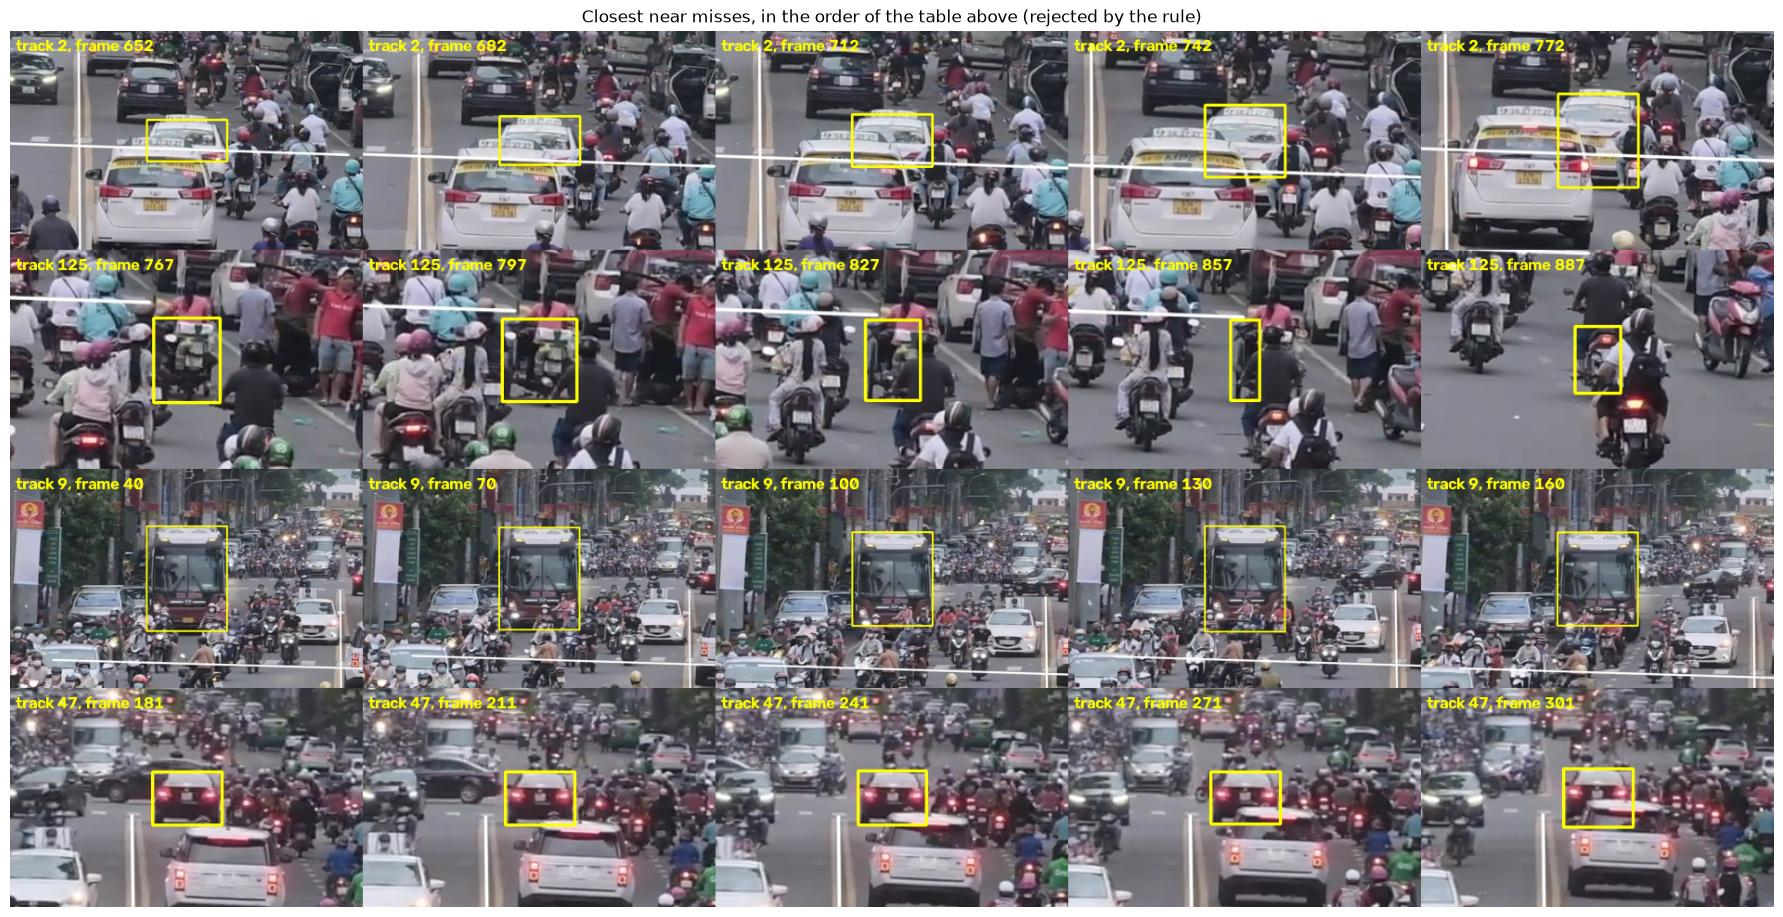

In [10]:
def evidence_strip(track_id: str, start_frame: int, end_frame: int, n: int = 5) -> np.ndarray:
    # Frames across a time span, with the track box and scene lines drawn, cropped around the vehicle.
    px = pixel_file["tracks"][track_id]
    indices = [i for i, f in enumerate(px["frames"]) if start_frame <= f <= end_frame]
    tiles = []
    for i in np.linspace(indices[0], indices[-1], n).round().astype(int):
        k = px["frames"][i]
        image = read_frame_at(SAMPLE_VIDEO, k)["image"]
        for line in scene["lines"]:
            if line["id"] in ("center_line", "near_row"):
                cv2.polylines(image, [np.round(reference_to_frame(camera_params[k], line["points"])).astype(np.int32)], False, (255, 255, 255), 2, cv2.LINE_AA)
        x1, y1, x2, y2 = (int(v) for v in px["bboxes"][i])
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 255), 2)
        half_w = max(170, int(2.2 * (x2 - x1)))
        half_h = int(half_w * 0.62)
        x0 = int(np.clip((x1 + x2) / 2 - half_w, 0, W - 2 * half_w))
        y0 = int(np.clip((y1 + y2) / 2 - half_h, 0, H - 2 * half_h))
        tile = cv2.resize(image[y0:y0 + 2 * half_h, x0:x0 + 2 * half_w], (380, 236), interpolation=cv2.INTER_AREA)
        cv2.putText(tile, f"track {track_id}, frame {k}", (6, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2, cv2.LINE_AA)
        tiles.append(tile)
    return np.hstack(tiles)


def save_event_evidence(event: dict) -> None:
    path = OUTPUT_DIR / f"{event['event_id']}.jpg"
    assert cv2.imwrite(str(path), evidence_strip(event["track_id"], event["start_frame"], event["end_frame"]))
    event["evidence"]["images"].append(str(path.relative_to(PROJECT_ROOT)))


for event in candidates:
    save_event_evidence(event)

strips = [evidence_strip(w["track_id"], w["start_frame"], w["end_frame"]) for w in near_misses[:5]]
near_miss_sheet = np.vstack(strips)
assert cv2.imwrite(str(OUTPUT_DIR / "near_misses.jpg"), near_miss_sheet)
fig, ax = plt.subplots(figsize=(18, 2.3 * len(strips)))
ax.imshow(cv2.cvtColor(near_miss_sheet, cv2.COLOR_BGR2RGB))
ax.set_title("Closest near misses, in the order of the table above (rejected by the rule)")
ax.axis("off")
fig.tight_layout()
plt.show()

## 5. Would the rule catch a real wrong-way vehicle?

A rule that reports nothing looks perfect on false positives, so we need a sensitivity test. This clip has no labeled wrong-way vehicle, so we create controlled ones: **reversing a real trajectory in time** turns a vehicle driving correctly into one travelling the wrong way along the same path, with realistic box sizes, jitter, occlusions and tracking noise. A vehicle moving away shrinks; reversed, it approaches and grows, as a real oncoming vehicle would.

**Which tracks count as test cases?** The definition must not depend on the rule's own thresholds, or the test only confirms itself. (A first version of this notebook required a track to move one box height *within 1 second*, the same limit as C3; it scored 5 of 5, which said little.) So a track is **eligible** if, over its whole time in a carriageway and at any speed, it travels at least one box height in the allowed direction.

These are injected for measurement only. They are never written to the candidates file.

**Caveat.** A reversed trajectory is not an independent wrong-way vehicle: real ones may weave or hesitate differently, so this measures the rule's sensitivity under favourable conditions, not its real-world recall.

In [11]:
def reversed_track(track: dict) -> dict:
    return {**track, "track_id": f"{track['track_id']}-reversed", "bottom_ref": track["bottom_ref"][::-1], "top_ref": track["top_ref"][::-1],
            "heights": track["heights"][::-1], "clipped": track["clipped"][::-1]}


def travel_along_road(track: dict) -> float:
    # Largest distance travelled in the allowed direction within one carriageway, in box heights, at any speed.
    bottom = smooth(track["bottom_ref"], RULE["smoothing_frames"])
    best = 0.0
    for region in scene["regions"]:
        if not region["allowed_direction"]:
            continue
        indices = [i for i, point in enumerate(bottom) if point_in_polygon(region["polygon"], point)]
        if len(indices) < 2:
            continue
        first, last = indices[0], indices[-1]
        allowed = allowed_direction_unit(region, (bottom[first] + bottom[last]) / 2, scene["vanishing_point"])
        best = max(best, float((bottom[last] - bottom[first]) @ allowed / np.median(track["heights"][indices])))
    return best


def usable_windows(track: dict, rule: dict) -> list[dict]:
    return [w for w in track_windows(track, scene, rule)[0] if usable(w, rule)]


def caught(windows_by_track: dict, track_ids, rule: dict) -> list:
    return [t for t in track_ids if any(not failed_conditions(w, rule) for w in windows_by_track[t])]


travel = {track_id: travel_along_road(track) for track_id, track in tracks.items()}
eligible = sorted(t for t, distance in travel.items() if distance >= 1.0)
print(f"Eligible tracks (travelled at least 1 box height along a carriageway, at any speed): {len(eligible)} of {len(tracks)}")

forward_windows = {t: usable_windows(track, RULE) for t, track in tracks.items()}
reversed_windows = {t: usable_windows(reversed_track(tracks[t]), RULE) for t in eligible}
caught_ids = caught(reversed_windows, eligible, RULE)
forward_false = caught(forward_windows, list(tracks), RULE)
missed_ids = sorted(set(eligible) - set(caught_ids))
print(f"Reversed versions caught by the rule: {len(caught_ids)} of {len(eligible)} ({len(caught_ids) / len(eligible):.0%})")
print(f"Real tracks flagged: {len(forward_false)} of {len(tracks)}")
print("Why the rest were missed:")
for t in missed_ids:
    windows = reversed_windows[t]
    if not windows:
        print(f"  track {t}: no usable {RULE['window_frames'] / FPS:.0f}-second window in a carriageway (length {len(tracks[t]['frames'])} frames)")
        continue
    best = max(windows, key=lambda w: w["opposing_heights"])
    print(f"  track {t}: best window {best['opposing_heights']:.2f} box heights, top edge {best['top_opposing_px']:.1f} px vs bottom {best['opposing_px']:.1f} px, failed: {', '.join(failed_conditions(best, RULE))}")

Eligible tracks (travelled at least 1 box height along a carriageway, at any speed): 15 of 136


Reversed versions caught by the rule: 10 of 15 (67%)
Real tracks flagged: 0 of 136
Why the rest were missed:
  track 109: no usable 2-second window in a carriageway (length 116 frames)
  track 12: best window 0.48 box heights, top edge 40.3 px vs bottom 65.5 px, failed: C3 distance
  track 124: no usable 2-second window in a carriageway (length 154 frames)
  track 3: best window 0.68 box heights, top edge 34.7 px vs bottom 81.2 px, failed: C3 distance
  track 66: best window 0.92 box heights, top edge 40.8 px vs bottom 47.7 px, failed: C3 distance


### Which window and threshold?

We sweep the window length and the distance threshold on both the real tracks and the reversed ones. The aim is to catch as many reversed tracks as possible while flagging no real track, which were all confirmed by eye to be travelling correctly (section 4). Slow vehicles need a longer window to cover a box height.

**Decision: a 2-second window with a threshold of 1 box height.**

- At 1 second and 1 box height, the rule catches only 5 of 15. Traffic here crawls, so few vehicles cover a box height that fast.
- At 2 seconds, it catches 10 of 15 with no real track flagged, without lowering the distance threshold.
- Lower thresholds catch only 1–2 more here. They were not chosen because the box-growth artifacts of section 2 reached about 0.5 box heights, so 1 box height keeps a clear margin.
- Windows longer than 2 seconds gain nothing, and they exclude shorter tracks.

This choice is tuned on 15 reversed tracks from one clip, so it needs checking on independent footage.

  window  threshold  real flagged  reversed caught  real flagged, no C4


    1.0s        0.5             0            11/15                    1
    1.0s       0.75             0             7/15                    0
    1.0s        1.0             0             5/15                    0
    1.0s       1.25             0             2/15                    0
    1.0s        1.5             0             0/15                    0
    1.0s        2.0             0             0/15                    0


    2.0s        0.5             0            12/15                    0
    2.0s       0.75             0            11/15                    0
    2.0s        1.0             0            10/15                    0
    2.0s       1.25             0             8/15                    0
    2.0s        1.5             0             4/15                    0
    2.0s        2.0             0             3/15                    0


    3.0s        0.5             0            11/15                    0
    3.0s       0.75             0            10/15                    0
    3.0s        1.0             0             8/15                    0
    3.0s       1.25             0             7/15                    0
    3.0s        1.5             0             7/15                    0
    3.0s        2.0             0             5/15                    0


    4.0s        0.5             0            11/15                    0
    4.0s       0.75             0            11/15                    0
    4.0s        1.0             0            10/15                    0
    4.0s       1.25             0             7/15                    0
    4.0s        1.5             0             7/15                    0
    4.0s        2.0             0             6/15                    0


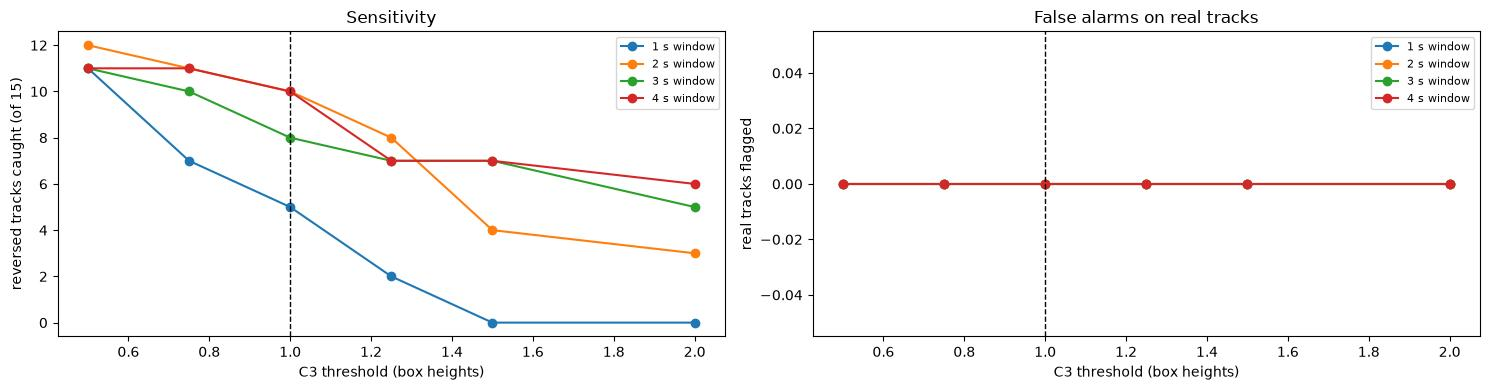

In [12]:
WINDOW_SWEEP = [60, 120, 180, 240]
THRESHOLD_SWEEP = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]
sweep_rows = []
print(f"{'window':>8} {'threshold':>10} {'real flagged':>13} {'reversed caught':>16} {'real flagged, no C4':>20}")
for window in WINDOW_SWEEP:
    base = {**RULE, "window_frames": window}
    real = {t: usable_windows(track, base) for t, track in tracks.items()}
    injected = {t: usable_windows(reversed_track(tracks[t]), base) for t in eligible}
    for threshold in THRESHOLD_SWEEP:
        rule = {**base, "min_opposing_heights": threshold}
        row = {"window_frames": window, "threshold": threshold, "real": len(caught(real, list(tracks), rule)), "reversed": len(caught(injected, eligible, rule)),
               "real_no_c4": len(caught(real, list(tracks), {**rule, "min_top_edge_share": -1e9}))}
        sweep_rows.append(row)
        print(f"{window / FPS:>7.1f}s {threshold:>10} {row['real']:>13} {row['reversed']:>13}/{len(eligible)} {row['real_no_c4']:>20}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for window in WINDOW_SWEEP:
    rows = [r for r in sweep_rows if r["window_frames"] == window]
    axes[0].plot([r["threshold"] for r in rows], [r["reversed"] for r in rows], "o-", label=f"{window / FPS:.0f} s window")
    axes[1].plot([r["threshold"] for r in rows], [r["real"] for r in rows], "o-", label=f"{window / FPS:.0f} s window")
axes[0].set(xlabel="C3 threshold (box heights)", ylabel=f"reversed tracks caught (of {len(eligible)})", title="Sensitivity")
axes[1].set(xlabel="C3 threshold (box heights)", ylabel="real tracks flagged", title="False alarms on real tracks")
for ax in axes:
    ax.axvline(RULE["min_opposing_heights"], color="k", linestyle="--", linewidth=1)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "threshold_sweep.png", dpi=100)
plt.show()

For visual confirmation, the injected events on the stabilized background. **These are synthetic, made by reversing real tracks.** The arrows show the direction of the injected motion, against the green allowed direction.

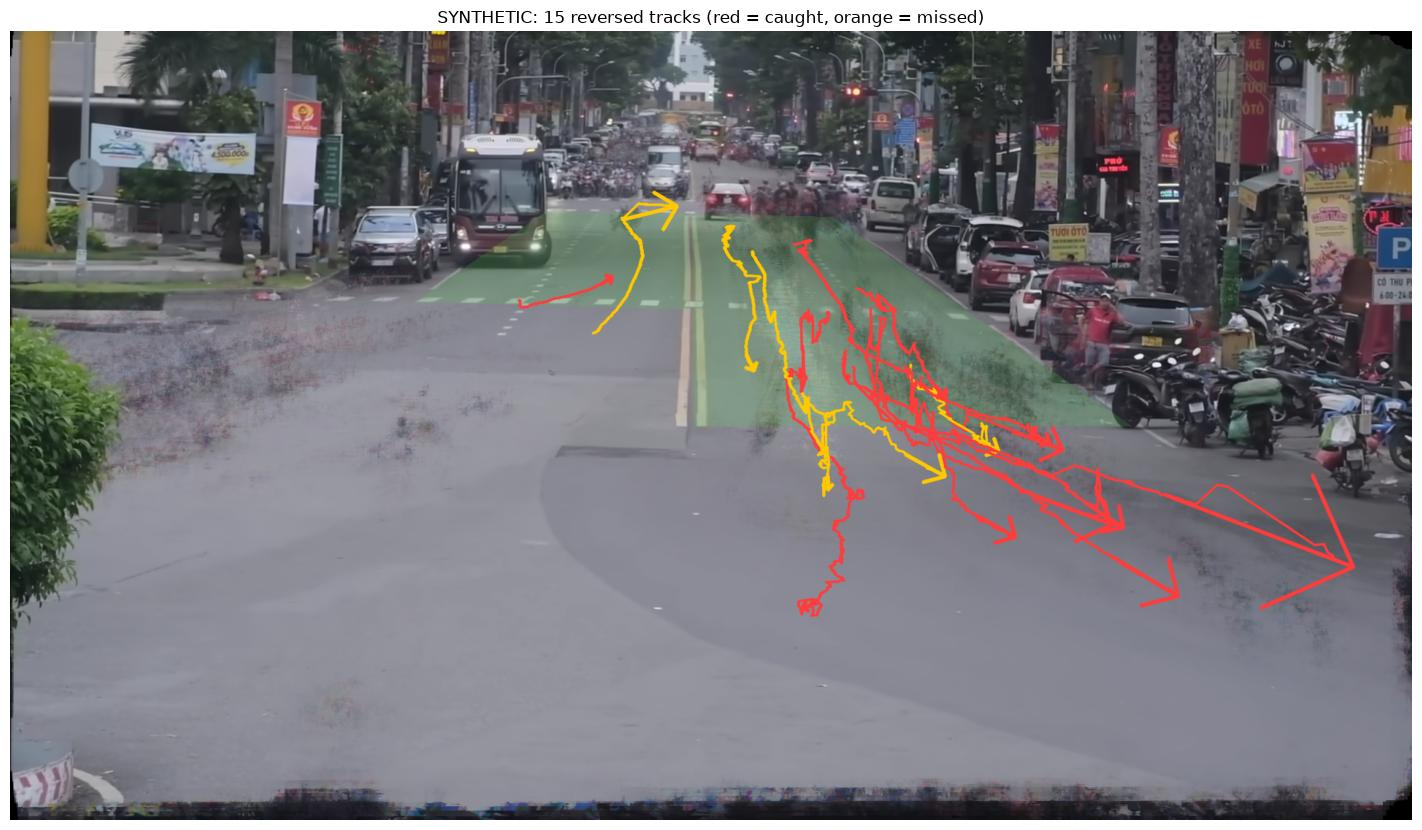

In [13]:
canvas = background.copy()
overlay = canvas.copy()
for region in scene["regions"]:
    if region["allowed_direction"]:
        cv2.fillPoly(overlay, [np.array(region["polygon"], dtype=np.int32)], (80, 200, 80))
canvas = cv2.addWeighted(overlay, 0.2, canvas, 0.8, 0)
for t in eligible:
    color = (60, 60, 255) if t in caught_ids else (0, 200, 255)
    points = tracks[t]["bottom_ref"][::-1]
    cv2.polylines(canvas, [points.astype(np.int32)], False, color, 2, cv2.LINE_AA)
    if len(points) > 40:
        cv2.arrowedLine(canvas, tuple(points[-40].astype(int).tolist()), tuple(points[-1].astype(int).tolist()), color, 3, cv2.LINE_AA, tipLength=0.5)
fig, ax = plt.subplots(figsize=(15, 8.4))
ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
ax.set_title(f"SYNTHETIC: {len(eligible)} reversed tracks (red = caught, orange = missed)")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "reversed_injection.jpg", dpi=90)
plt.show()

## 6. False positives and false negatives

**False positives on real data** are the candidates and near misses in section 4, which can be reviewed by eye.

**False negatives have two sources:**

1. *The rule misses a vehicle it can see.* Section 5 measured this.
2. *The vehicle never becomes a usable track.* The rule cannot see what the detector and tracker lost. The tracking data tells us how much traffic is affected:

In [14]:
def region_track_statistics() -> dict:
    stats = {}
    for region in scene["regions"]:
        if not region["allowed_direction"]:
            continue
        seen = evaluated = 0
        for track_id, track in tracks.items():
            if any(point_in_polygon(region["polygon"], p) for p in track["bottom_ref"][::5]):
                seen += 1
                if any(w["region_id"] == region["id"] for w in forward_windows[track_id]):
                    evaluated += 1
        stats[region["id"]] = {"tracks_seen": seen, "tracks_with_usable_window": evaluated}
    return stats


coverage = region_track_statistics()
for region_id, values in coverage.items():
    print(f"{region_id:<20} {values['tracks_seen']:>3} tracks seen, {values['tracks_with_usable_window']:>3} have at least one usable {RULE['window_frames'] / FPS:.0f}-second window")

left_carriageway       5 tracks seen,   4 have at least one usable 2-second window
right_carriageway     25 tracks seen,  16 have at least one usable 2-second window


**An independent check without the detector.** Dense optical flow estimates per-pixel motion between aligned frames, so it can reveal movement against the allowed direction even when no track exists. We sample a pair of frames 0.25 s apart every 0.5 s and mark blocks moving clearly against the allowed direction.

Flow has its own failure modes (shadows, reflections, occlusion edges), so this is a screening tool: it tells us where to look, not what happened. A screening result of zero means nothing unless the tool can detect the thing at all, so we add a **positive control**: the same frame pairs with their order swapped, which reverses all motion and should turn "along" into "against".

In [15]:
FLOW_LAG, FLOW_EVERY, FLOW_SCALE, BLOCK = 15, 30, 0.5, 24
MIN_FLOW_PX = 3.0  # full-resolution px per 0.25 s: slow crawling does not count
wanted = set()
for k in range(0, N_FRAMES - FLOW_LAG, FLOW_EVERY):
    wanted |= {k, k + FLOW_LAG}
aligned_gray = {}
for record in iter_frames(SAMPLE_VIDEO):
    k = record["frame_index"]
    if k in wanted:
        aligned = cv2.warpAffine(record["image"], similarity_matrix(camera_params[k]), (W, H))
        aligned_gray[k] = cv2.resize(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), None, fx=FLOW_SCALE, fy=FLOW_SCALE, interpolation=cv2.INTER_AREA)

directional = [r for r in scene["regions"] if r["allowed_direction"]]
vp = scene["vanishing_point"]


def screen_flow(swap_order: bool) -> tuple[dict, list[dict]]:
    # Count blocks moving along and against the allowed direction; swap_order reverses time as a positive control.
    counts = {r["id"]: {"against": 0, "along": 0} for r in directional}
    events = []
    for k in range(0, N_FRAMES - FLOW_LAG, FLOW_EVERY):
        first, second = (k + FLOW_LAG, k) if swap_order else (k, k + FLOW_LAG)
        flow = cv2.calcOpticalFlowFarneback(aligned_gray[first], aligned_gray[second], None, 0.5, 3, 21, 3, 5, 1.1, 0)
        for y in range(0, flow.shape[0] - BLOCK, BLOCK):
            for x in range(0, flow.shape[1] - BLOCK, BLOCK):
                position = ((x + BLOCK / 2) / FLOW_SCALE, (y + BLOCK / 2) / FLOW_SCALE)
                region = next((r for r in directional if point_in_polygon(r["polygon"], position)), None)
                if region is None:
                    continue
                motion = flow[y:y + BLOCK, x:x + BLOCK].reshape(-1, 2).mean(axis=0) / FLOW_SCALE
                magnitude = float(np.linalg.norm(motion))
                if magnitude < MIN_FLOW_PX:
                    continue
                cosine = float(motion @ allowed_direction_unit(region, position, vp) / magnitude)
                if cosine >= 0.5:
                    counts[region["id"]]["along"] += 1
                elif cosine <= -0.5:
                    counts[region["id"]]["against"] += 1
                    events.append({"frame": k, "region_id": region["id"], "x": position[0], "y": position[1], "px": magnitude})
    return counts, events


sample_counts, flow_events = screen_flow(swap_order=False)
control_counts, _ = screen_flow(swap_order=True)
for label, counts in (("real order", sample_counts), ("POSITIVE CONTROL, time swapped", control_counts)):
    print(label)
    for region_id, values in counts.items():
        total = values["along"] + values["against"]
        print(f"  {region_id:<20} moving blocks: {total:>5} | along the allowed direction {values['along']:>5} | against {values['against']:>5} ({values['against'] / max(total, 1):.1%})")

per_frame = {}
for e in flow_events:
    per_frame.setdefault((e["frame"], e["region_id"]), []).append(e)
top_samples = sorted(per_frame.items(), key=lambda kv: -len(kv[1]))[:6]
print("Samples with the most blocks moving against the allowed direction:", [(f, r, len(v)) for (f, r), v in top_samples])

if top_samples:
    fig, axes = plt.subplots(2, 3, figsize=(18, 8))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, ((k, region_id), events) in zip(axes.ravel(), top_samples):
        aligned = cv2.warpAffine(read_frame_at(SAMPLE_VIDEO, k)["image"], similarity_matrix(camera_params[k]), (W, H))
        for e in events:
            cv2.circle(aligned, (int(e["x"]), int(e["y"])), 10, (0, 0, 255), 2)
        xs, ys = [e["x"] for e in events], [e["y"] for e in events]
        x0, y0 = int(np.clip(np.mean(xs) - 330, 0, W - 660)), int(np.clip(np.mean(ys) - 190, 0, H - 380))
        ax.imshow(cv2.cvtColor(aligned[y0:y0 + 380, x0:x0 + 660], cv2.COLOR_BGR2RGB))
        ax.set_title(f"frame {k} ({k / FPS:.1f} s), {region_id}: {len(events)} blocks against", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "flow_screening.jpg", dpi=85)
    plt.show()

real order
  left_carriageway     moving blocks:   347 | along the allowed direction   347 | against     0 (0.0%)
  right_carriageway    moving blocks:  1147 | along the allowed direction  1147 | against     0 (0.0%)
POSITIVE CONTROL, time swapped
  left_carriageway     moving blocks:   339 | along the allowed direction     0 | against   339 (100.0%)
  right_carriageway    moving blocks:  1166 | along the allowed direction     0 | against  1166 (100.0%)
Samples with the most blocks moving against the allowed direction: []


## 7. Save the results

In [16]:
track_statuses = {track_id: {"status": r["status"], "class_name": tracks[track_id]["class_name"], "evaluable_windows": r["evaluable_windows"]} for track_id, r in results.items()}
candidates_path = OUTPUT_DIR / "video-test.wrong_way.candidates.json"
candidates_path.write_text(json.dumps({
    "video_id": "video-test",
    "tracking_session": TRACKING_SESSION,
    "scene_id": scene["scene_id"],
    "rule": RULE,
    "note": "Candidates require human review. Synthetic and injected events are never stored here.",
    "status_counts": status_counts,
    "candidates": candidates,
    "track_statuses": track_statuses,
}, indent=2))

evaluation_path = OUTPUT_DIR / "rule_evaluation.json"
evaluation_path.write_text(json.dumps({
    "scenarios": scenario_results,
    "near_misses": [{k: w[k] for k in ("track_id", "class_name", "region_id", "start_frame", "end_frame", "opposing_heights", "opposing_px", "top_opposing_px", "angle_to_opposite_deg", "failed")} for w in near_misses[:20]],
    "reversal_injection": {"eligible": eligible, "caught": caught_ids, "missed": missed_ids, "forward_flagged": forward_false},
    "eligibility": "travelled at least 1 box height along a carriageway, at any speed",
    "threshold_sweep": sweep_rows,
    "region_track_statistics": coverage,
    "flow_screening": sample_counts,
    "flow_positive_control": control_counts,
}, indent=2))
for path in (candidates_path, evaluation_path):
    print("wrote", path.relative_to(PROJECT_ROOT), f"({path.stat().st_size / 1e3:.0f} KB)")

wrote outputs/05_violation_detection/video-test.wrong_way.candidates.json (17 KB)
wrote outputs/05_violation_detection/rule_evaluation.json (9 KB)


## 8. Validation

In [17]:
REQUIRED_EVENT_FIELDS = {"event_id", "video_id", "violation_type", "tracking_session", "track_id", "class_name", "region_id", "start_frame", "trigger_frame", "end_frame",
                         "start_time_s", "trigger_time_s", "end_time_s", "rule", "why", "evidence", "license_plate", "review_status"}
reloaded = json.loads(candidates_path.read_text())
events_to_check = reloaded["candidates"] + [example_event]
ids = [e["event_id"] for e in events_to_check]

checks = {
    "all scenarios behave as required": all(r["passed"] for r in scenario_results),
    "every track has exactly one known status": set(reloaded["track_statuses"]) == set(tracks)
        and {v["status"] for v in reloaded["track_statuses"].values()} <= {"candidate", "no_violation", "not_evaluable", "not_in_directional_region"},
    "status counts add up to the number of tracks": sum(reloaded["status_counts"].values()) == len(tracks),
    "events have all required fields": all(REQUIRED_EVENT_FIELDS <= set(e) for e in events_to_check),
    "every event is pending, never confirmed": all(e["review_status"] == "pending" for e in events_to_check),
    "event ids are unique and differ from track ids": len(set(ids)) == len(ids) and not set(ids) & set(tracks),
    "events are ordered in time": all(e["start_frame"] <= e["trigger_frame"] <= e["end_frame"] for e in events_to_check),
    "no synthetic track id in the stored candidates": not any("reversed" in e["track_id"] for e in reloaded["candidates"]),
    "a lost direction yields no candidate": evaluate_track(SCENARIOS[-1][1], scene_without_direction, RULE)["events"] == [],
    "no real track above 1 box height is left unflagged": all(any(not failed_conditions(w, RULE) for w in forward_windows[t]) or not any(w["opposing_heights"] >= RULE["min_opposing_heights"] and w["angle_to_opposite_deg"] <= w["tolerance_deg"] and w["top_opposing_px"] >= RULE["min_top_edge_share"] * w["opposing_px"] for w in forward_windows[t]) for t in tracks),
    "flow positive control: swapping time turns motion against the allowed direction": all(control_counts[r]["against"] > sample_counts[r]["against"] and control_counts[r]["against"] > 0 for r in control_counts),
    "the rule catches reversed tracks": len(caught_ids) > 0,
}
for name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")
assert all(checks.values()), "One or more checks failed - see above"

[PASS] all scenarios behave as required
[PASS] every track has exactly one known status
[PASS] status counts add up to the number of tracks
[PASS] events have all required fields
[PASS] every event is pending, never confirmed
[PASS] event ids are unique and differ from track ids
[PASS] events are ordered in time
[PASS] no synthetic track id in the stored candidates
[PASS] a lost direction yields no candidate
[PASS] no real track above 1 box height is left unflagged
[PASS] flow positive control: swapping time turns motion against the allowed direction
[PASS] the rule catches reversed tracks


## Results

All numbers come from the outputs above.

**On the real clip: no candidate events.**

- Of 136 tracks, 20 were evaluated with no violation, 10 could not be evaluated, and 106 were never in a region with a direction.
- The largest opposing movement in any usable window is 0.43 box heights, against a threshold of 1.
- The closest near misses were inspected by eye, and all travel the allowed way: rear views with tail lights on the right carriageway, and a bus facing the camera on the left.
- Optical flow, which does not use the detector, found 0 of 1,494 moving blocks going against the allowed direction. Swapping time as a positive control turned all 1,505 moving blocks into "against", so the tool can see such motion.

So this clip shows **no evidence of wrong-way driving**. That is not proof that none occurred; see the limits below.

**Valid and invalid scenarios.** All 15 synthetic scenarios behave as required. They cover correct and wrong directions, slow creep, sideways crossing, noise, a box that only grows, short or gapped or clipped tracks, regions without a direction, and a scene that lost its direction.

**Sensitivity, measured by reversing real trajectories.** The rule catches **10 of 15** reversed tracks (67%) and flags no real track.

- 2 of the missed tracks have no usable 2-second window.
- 3 stay below one box height (0.48, 0.68 and 0.92).

**What changed along the way, and why.**

- *An inflated first result.* The first sensitivity test scored 5 of 5, because its test cases were selected with the rule's own distance limit. With a definition independent of the rule, that same 1-second setting catches only 5 of 15. The 2-second window came from this correction.
- *The value of each condition.* At a 1-second window and a threshold of 0.5, one real track is flagged without condition C4, and none with it. The first inspection showed why: boxes that grow when a vehicle emerges from behind another look like backward motion.

**Direction support.** The left carriageway's direction has weak support from tracks (14 segments, 71% agreement), but optical flow agrees with it in all 347 moving blocks. Events there are still labelled `weak`, because the label only uses the tracking statistics.

## False positives and false negatives

- **False positives:** none on this clip. A clip with no positive cases says little about precision elsewhere, and the rule has never been tested on a real wrong-way vehicle.
- **False negatives, for a vehicle with a usable track:** at least 1 in 3 under favourable conditions, mainly slow vehicles.
- **False negatives, without a usable track:** the rule cannot see them. On the two carriageways, 10 of 30 tracks seen have no usable 2-second window, and vehicles the detector missed never appear at all.

## Limitations

- **No real positive case.** Everything about sensitivity rests on synthetic scenarios and reversed trajectories, which are not independent wrong-way vehicles.
- **Tuned on one clip.** The window and threshold were chosen on 15 reversed tracks from the same 15-second clip, and need checking on independent footage.
- **Limited coverage.** Most traffic is in the junction (106 of 136 tracks), where no direction applies, so the rule says nothing about it.
- **Slow and short movements are missed by design.** Moving less than one box height in 2 seconds is not flagged, and a track must last at least 2 seconds. Detection is therefore delayed by up to 2 seconds, which is fine offline but matters for live use.
- **The flow check is coarse.** Blocks are about 48 px at full resolution, so a small motorcycle among correct traffic may be averaged away, and motion under about 3 px per 0.25 s is ignored.
- **Inherited errors.** Position jitter and fragmentation from tracking remain. The scene geometry and its assumptions come from Notebook 04.

## Conclusion

**Completion criterion** — *the selected rule reliably produces candidate events in representative scenarios and does not silently treat missing traffic conditions as confirmed violations*:

- **Missing conditions: met.** Unusable tracks are reported as `not_evaluable`, a region without a direction yields no event, and every event stays `pending`.
- **Producing candidates: only partly met.** It works in all synthetic scenarios, but catches 67% of reversed tracks, and no real wrong-way vehicle has been available to test it on.

**Readiness for integration.**

- The rule and its status logic stay in this notebook until Notebook 07 settles the event schema, and should then move to `src/traffic_violation_detection/` with tests.
- The candidates file for this clip holds no events, so Notebooks 06–07 need another source of vehicles or clearly labelled synthetic events to test with.

**Next steps.**

- **Footage with a real violation** is the most valuable addition, both for this rule and for a red-light rule.
- **Notebook 06 — license plate recognition** can proceed on tracked vehicles whose rear plates are visible in the near field.